In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split,cross_val_score,KFold,learning_curve,GridSearchCV
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression,Lasso,Ridge,ElasticNet
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score,mean_squared_error



RANDOM_STATE=42
cvfolds=KFold(5,shuffle=True,random_state=RANDOM_STATE)
max_iter=100000

In [3]:
df=pd.read_csv('Advertising.csv',header=0)
df.head(5)
df.info()
df.duplicated().sum()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


(200, 4)

no duplicates , no nulls, no datatype issues

In [4]:
df.columns=df.columns.str.lower()
df.columns

Index(['tv', 'radio', 'newspaper', 'sales'], dtype='object')

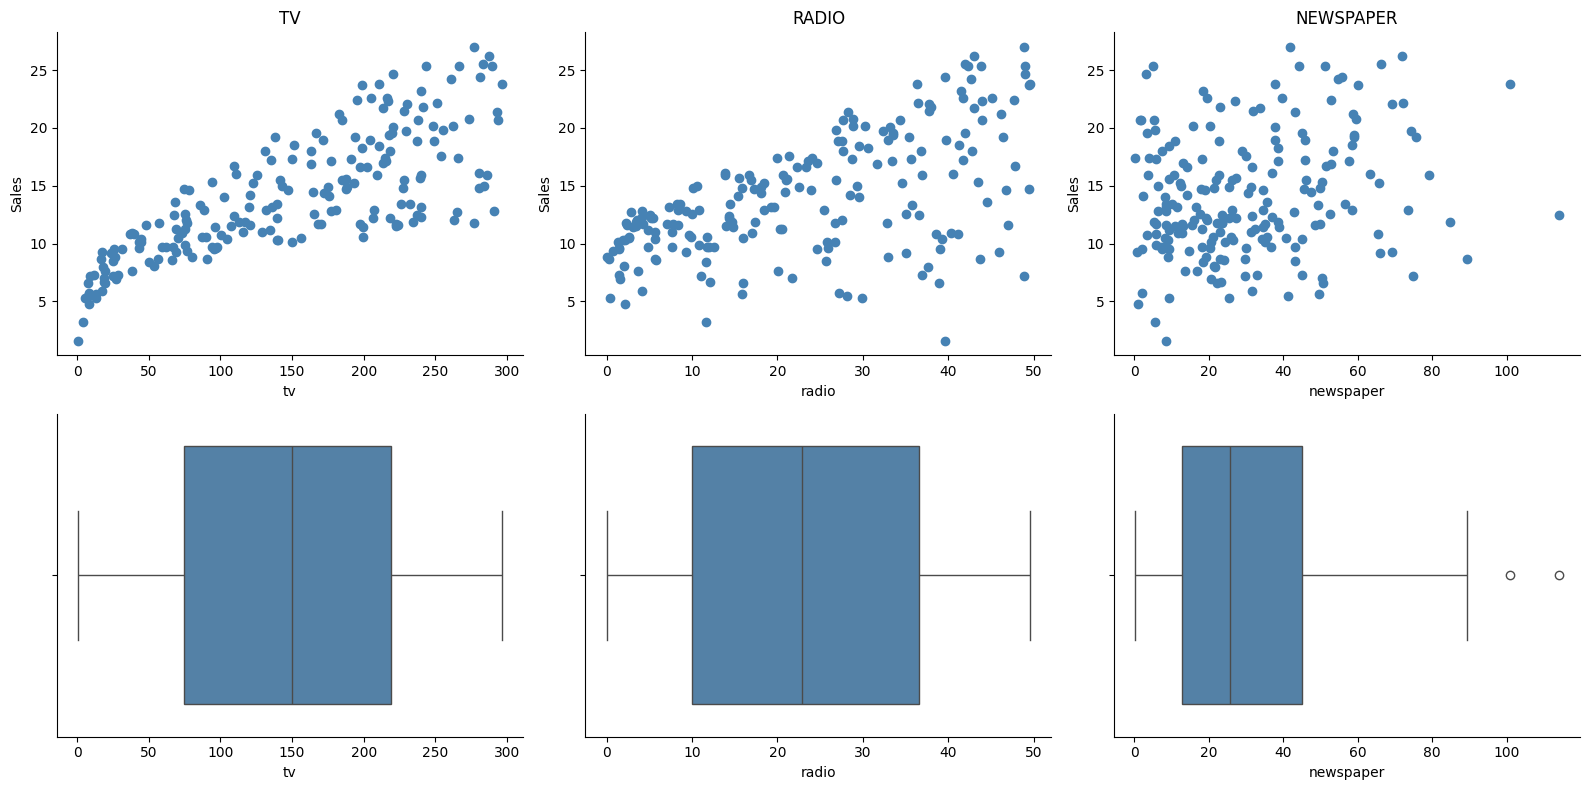

In [5]:
cols = ['tv', 'radio', 'newspaper']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(cols):
    
    axes[0, i].scatter(df[col], df['sales'], marker='o', color='steelblue')
    axes[0, i].set_title(col.upper())
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel('Sales')

    
    sns.boxplot(x=df[col], ax=axes[1, i], color='steelblue')
    axes[1, i].set_xlabel(col)

for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()


relationship seems almost linear, tv scatter is curved we may need polynomial features , 
also the the outliers in newspaper seem marginal not influenctial as their corresponding sales is normal 
y is cont 

C:\Users\risha\AppData\Roaming\Python\Python313\site-packages\seaborn\categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


(np.float64(0.4075714250767127), np.float64(-0.40886922014994376))

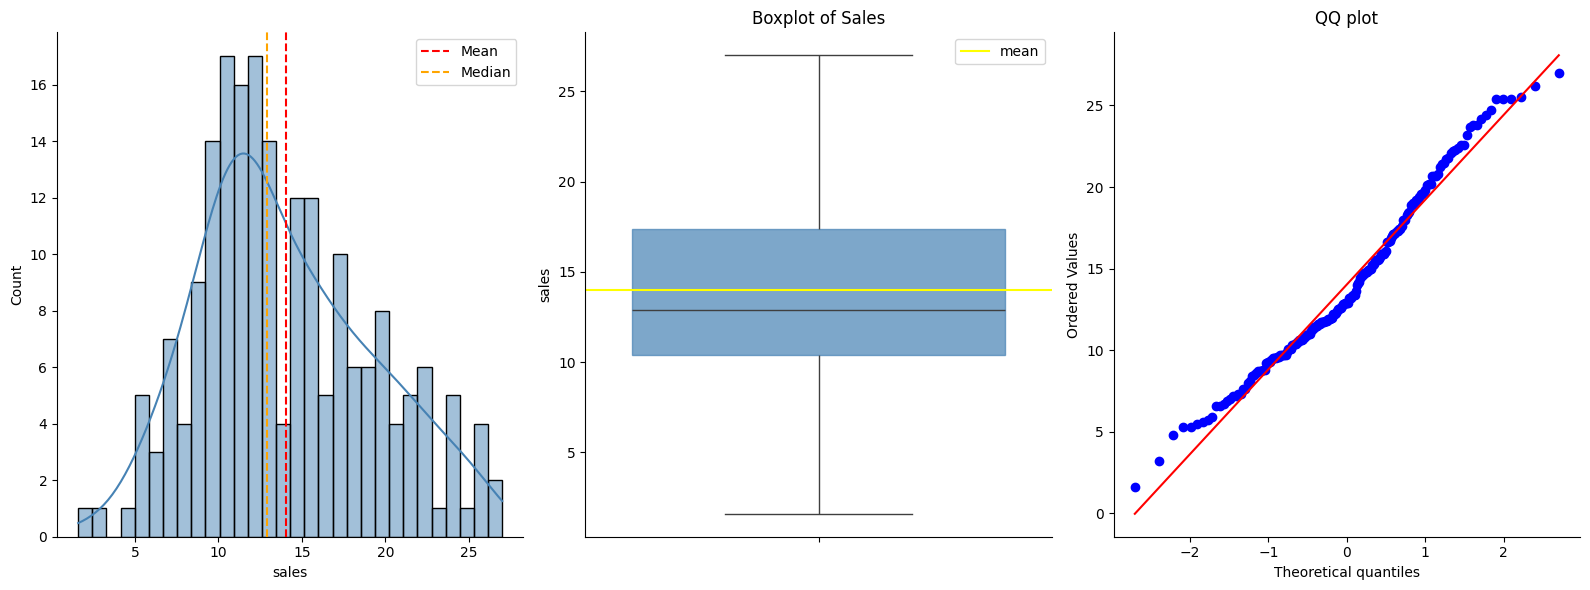

In [6]:
fig,axes=plt.subplots(1,3,figsize=(16,6))
sns.histplot(df,x=df['sales'],bins=30,kde=True,color='steelblue',edgecolor='black',linewidth=1,ax=axes[0])
axes[0].axvline(df['sales'].mean(),c='r',linestyle='--',label='Mean')
axes[0].axvline(df['sales'].median(),c='orange',linestyle='--',label='Median')
axes[0].legend(loc='best')

sns.boxplot(df,y=df['sales'],patch_artist=True,boxprops=dict(color='steelblue',alpha=0.7),ax=axes[1])
axes[1].axhline(df['sales'].mean(),c='yellow',linestyle='-',label='mean')
axes[1].legend(loc='best')
axes[1].set_title('Boxplot of Sales')

_=stats.probplot(df['sales'],dist='norm',plot=axes[2])
axes[2].set_title('QQ plot')

for ax in axes:
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
df['sales'].skew(),df['sales'].kurtosis()

ditribution seems normal , with mild right skew. log may help , but lets skip for now.

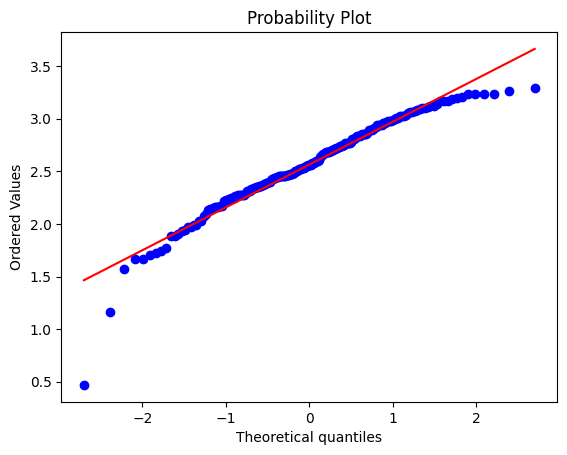

In [7]:
fig,axes=plt.subplots()
_=stats.probplot(np.log(df['sales']),dist='norm',plot=axes)

<Axes: >

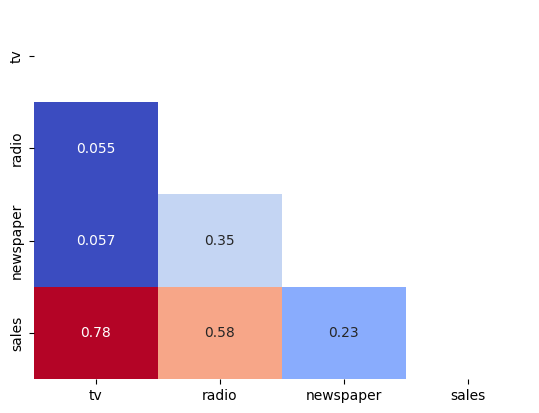

In [8]:
mask=np.triu(np.ones_like(df.corr()))
sns.heatmap(df.corr(),mask=mask,annot=True,cbar=False,cmap='coolwarm')

small multicollinearity ,
news and radio has bit higher multicollinearity , lets confirm with VIF,but first lets split into train test to avoid data leakage

In [9]:
X=df.drop('sales',axis=1)
y=df['sales']

In [10]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=RANDOM_STATE)

In [11]:
X_c=sm.add_constant(X_train)
vif=pd.DataFrame({
    'features':X_c.columns,
    'vif':[variance_inflation_factor(X_c.values,i) for i in range(X_c.shape[1])]})
vif[vif['features']!='const']

,features,vif
1,tv,1.002915
2,radio,1.180305
3,newspaper,1.177309


all values are less than 5 , so we are fine with multicollinearity . so most gauss-markov assumptions are satisfied , lets start wih linear regression. first lets check for outliers


In [12]:
def iqr_flags(s):
    Q1, Q3 = s.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    return (s < Q1 - 1.5*IQR) | (s > Q3 + 1.5*IQR)

flags = X_train.apply(iqr_flags)
flags.sum()                         
X_train[flags.any(axis=1)]
     

,tv,radio,newspaper
101,296.4,36.3,100.9


In [13]:
pd.concat([X_train, y_train], axis=1).apply(iqr_flags).sum()

tv           0
radio        0
newspaper    1
sales        0
dtype: int64

In [14]:
y_train[pd.concat([X_train,y_train],axis=1).apply(iqr_flags).any(axis=1)]

101    23.8
Name: sales, dtype: float64

In [15]:
#baseline
dummy = DummyRegressor(strategy='mean')
dummyCV = cross_val_score(dummy, X_train, y_train, cv=cvfolds,
                          scoring='neg_mean_squared_error')
dummyMSE = -dummyCV.mean()

print(f"Dummy MSE: {dummyMSE:.2f}")


Dummy MSE: 26.68


In [16]:


baseline_model=Pipeline([('scalar',StandardScaler()),
                         ('model',LinearRegression())])
baseline_model.fit(X_train,y_train)

baseline_pred=baseline_model.predict(X_train)
baseline_resid=y_train-baseline_pred

baselineCV=cross_val_score(baseline_model,X_train,y_train,cv=cvfolds,scoring='neg_mean_squared_error')
r2 = cross_val_score(baseline_model, X_train, y_train, cv=cvfolds, scoring='r2')


baslineMSE=-baselineCV.mean()
baslineRMSE=np.sqrt(-baselineCV)

print(f"Dummy MSE: {dummyMSE:.2f}")
print(f"Model MSE: {baslineMSE:.2f}")
print(f"Improvement: {dummyMSE / baslineMSE:.1f}×")
print(f"R²: {1 - baslineMSE / dummyMSE:.3f}")
print(f"RMSE: {baslineRMSE.mean():.3f} ± {baslineRMSE.std():.3f}")
print(f"R² CV: {r2.mean():.3f} ± {r2.std():.3f}")
baslineMSE,y_train.mean(),y_train.std()



Dummy MSE: 26.68
Model MSE: 2.88
Improvement: 9.3×
R²: 0.892
RMSE: 1.676 ± 0.266
R² CV: 0.870 ± 0.072


(np.float64(2.8791012107235505),
 np.float64(14.1),
 np.float64(5.108754355924973))

In [17]:
outlier_mask=np.abs(baseline_resid)>3*baseline_resid.std()
outliers=pd.DataFrame({
    'fitted': baseline_pred[outlier_mask],
    'actual': y_train[outlier_mask],
    'resid': baseline_resid[outlier_mask]
}).join(X_train[outlier_mask])
outliers

,fitted,actual,resid,tv,radio,newspaper
5,12.826936,7.2,-5.626936,8.7,48.9,75.0
130,10.526524,1.6,-8.926524,0.7,39.6,8.7


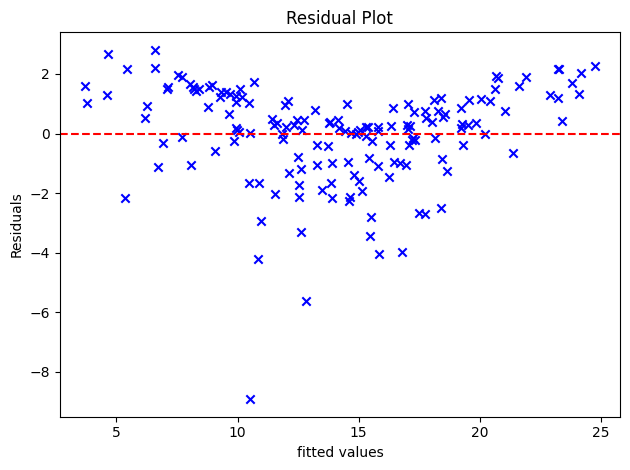

In [18]:
plt.figure()
plt.scatter(x=baseline_pred,y=baseline_resid,marker='x',c='b')
plt.title('Residual Plot')
plt.xlabel('fitted values')
plt.ylabel('Residuals')
plt.axhline(y=0,c='r',linestyle='--')
plt.tight_layout()



there seems to be small heteroscedascity , and the classic curve shows non linearity 

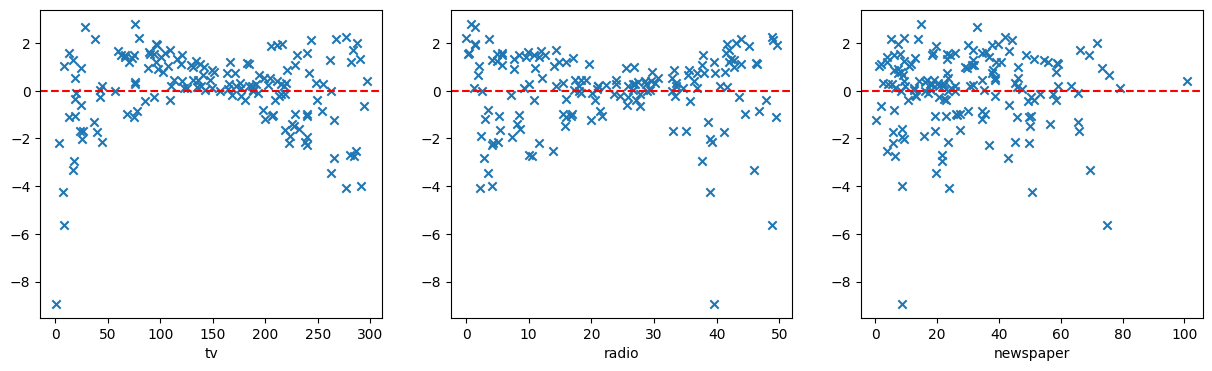

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['tv', 'radio', 'newspaper']):
    ax.scatter(X_train[col], baseline_resid, marker='x')
    ax.axhline(0, c='r', ls='--')
    ax.set_xlabel(col)

the tv scatter had cruve and residual is downward U . radio scatter was linear , the residual is upward U (as scatter was linear, only other possibilty interaction) , so radio needs an interaction term.
The tv scatter (image 1 earlier) rises steeply from tv=0 to ~100, then flattens toward 300.  diminishing returns to ad spend. It's monotone increasing with decreasing slope — which is what log and √ do,

Mechanically: if the true model is $y = \beta_1 tv + \beta_2 radio + \beta_3 (tv \cdot radio)$ and you omit the product, the residual carries $\beta_3 (tv \cdot radio)$. Project that onto the radio axis and, because tv and radio are roughly uncorrelated ($\text{VIF} \approx 2.5\text{--}3.5$, so not independent but not collinear either), you get systematic structure that curves.

Domain logic points the same way: TV builds awareness, radio converts it. Spending on both should beat the sum of spending on either. That's a multiplicative effect.

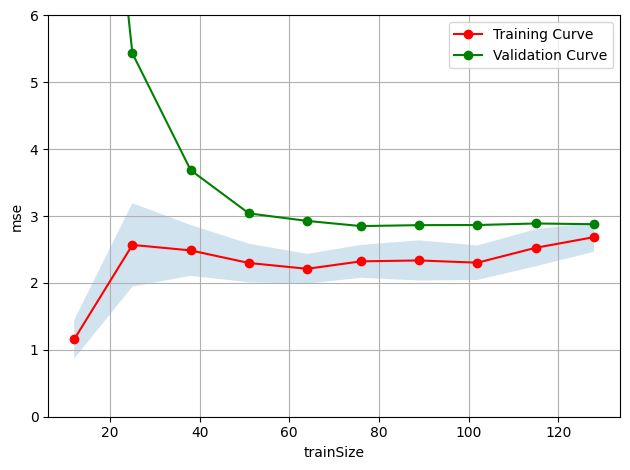

In [20]:
train_size,train_score,test_score=learning_curve(baseline_model,X_train,y_train,scoring='neg_mean_squared_error',random_state=RANDOM_STATE,train_sizes=np.linspace(0.1,1,10),cv=cvfolds)
train_mean, train_std = -train_score.mean(1), train_score.std(1)
plt.figure()
plt.plot(train_size,train_mean,'o-',c='r',label='Training Curve')
plt.plot(train_size,-test_score.mean(axis=1),'o-',c='g',label='Validation Curve')
plt.fill_between(train_size, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.xlabel('trainSize')
plt.ylabel('mse')
plt.legend(loc='best');plt.grid(True)
plt.ylim(0,6)
plt.tight_layout()




In [21]:
alphas=np.logspace(-3,3,30)

def hyperparameter_tuning(model):
    p=Pipeline([('poly',PolynomialFeatures(include_bias=False)),('scalar',StandardScaler()),('model',model)])

    if isinstance(model,(Ridge,Lasso)):
        params_grid={'poly__degree':np.arange(1,5),
                     'model__alpha':alphas
                     }
    else:
        params_grid={'poly__degree':np.arange(1,5),
                     'model__alpha':alphas,
                     'model__l1_ratio':[0.1,.3,.5,.7,.9,.95,1]
                      }
    g=GridSearchCV(p,params_grid,scoring='neg_mean_squared_error',cv=cvfolds,n_jobs=-1)
    g.fit(X_train,y_train)
    return g

Llasso_g=hyperparameter_tuning(Lasso(max_iter=max_iter))
lasso_best_params,lasso_mseCV=Llasso_g.best_params_,-Llasso_g.best_score_
ridge_g=hyperparameter_tuning(Ridge())
ridge_best_params,ridge_mseCV=ridge_g.best_params_,-ridge_g.best_score_
ElasticNet_g=hyperparameter_tuning(ElasticNet(max_iter=max_iter))
ElasticNet_best_params,ElasticNet_mseCV=ElasticNet_g.best_params_,-ElasticNet_g.best_score_
print(f'Lasso : Best Params {lasso_best_params} CV_MSE {lasso_mseCV}')
print(f'Ridge : Best Params {ridge_best_params} CV_MSE {ridge_mseCV}')
print(f'ElasticNet : Best Params {ElasticNet_best_params} CV_MSE {ElasticNet_mseCV}')



Lasso : Best Params {'model__alpha': np.float64(0.0016102620275609393), 'poly__degree': np.int64(3)} CV_MSE 0.41420820441238726
Ridge : Best Params {'model__alpha': np.float64(0.006723357536499335), 'poly__degree': np.int64(4)} CV_MSE 0.49801683336976127
ElasticNet : Best Params {'model__alpha': np.float64(0.0016102620275609393), 'model__l1_ratio': 1, 'poly__degree': np.int64(3)} CV_MSE 0.41420820441238726


lasso clearly wins

In [22]:
final_pipeline=Llasso_g.best_estimator_

In [23]:
feature_names=final_pipeline.named_steps['poly'].get_feature_names_out(input_features=X_train.columns)
feature_values=final_pipeline.named_steps['model'].coef_
featureValues=pd.DataFrame({'features':feature_names,
                            'values':feature_values}).sort_values('values',key=abs,ascending=False)
featureValues

,features,values
3,tv^2,-9.192258
0,tv,6.894421
9,tv^3,4.119615
4,tv radio,4.087758
5,tv newspaper,-0.758825
10,tv^2 radio,-0.590778
11,tv^2 newspaper,0.498746
2,newspaper,0.387912
1,radio,0.338803
12,tv radio^2,0.243463


the cubic terms are causing the issue
tv (+6.89), tv² (−9.19), tv³ (+4.12) produce a saturating shape through cancellation — three large opposing numbers summing to something modest. Two consequences:

Instability. Refit on a bootstrap resample and those three coefficients will move substantially, even though predictions barely change. They're not individually identified; only their combination is. That's why we can't interpret them.

Extrapolation failure. A cubic does whatever it wants outside the training range. With tv³ positive, predicted sales accelerate upward past tv≈300. With the interior curvature negative, there's likely a downward bend near the boundary too. Both are nonsense for ad spend, and both are invisible in a CV score computed entirely inside the data range.

That second point is the one that matters for production. Our CV number says nothing about behavior at tv=350, and a marketing team asking "what if we double spend" is asking exactly that.

What this doesn't do: hurt our  in-range CV score much. 0.414 is a real number and the polynomial genuinely fits. Extra features hurt generalization and interpretability before they hurt CV — which is precisely why CV alone shouldn't decide this.

min: degree 3, alpha 0.0016, MSE 0.414, SE 0.176
threshold: 0.590
1-SE pick: degree 2, alpha 0.0281, MSE 0.547


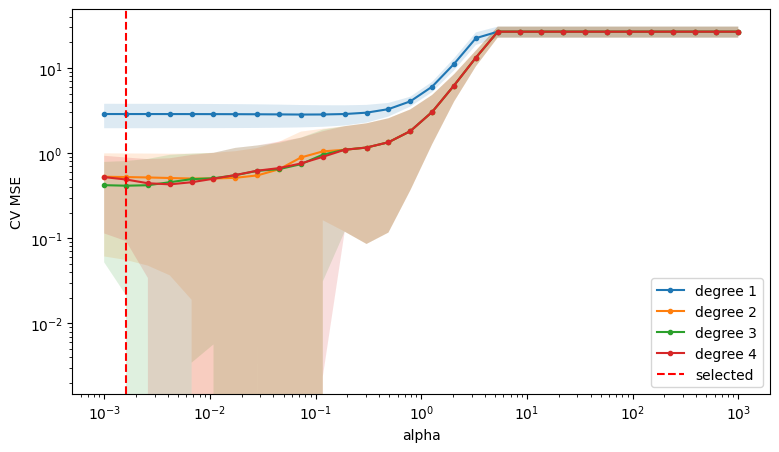

In [24]:

res = pd.DataFrame(Llasso_g.cv_results_)
res['mse'] = -res['mean_test_score']
res['std'] = res['std_test_score']
res['se']  = res['std_test_score'] / np.sqrt(5)

fig, ax = plt.subplots(figsize=(9, 5))
for deg in sorted(res['param_poly__degree'].unique()):
    sub = res[res['param_poly__degree'] == deg].sort_values('param_model__alpha')
    ax.plot(sub['param_model__alpha'], sub['mse'], marker='.', label=f'degree {deg}')
    ax.fill_between(sub['param_model__alpha'],
                    sub['mse'] - sub['std'], sub['mse'] + sub['std'], alpha=0.15)

ax.set_xscale('log')
ax.set_xlabel('alpha'); ax.set_ylabel('CV MSE')
ax.axvline(lasso_best_params['model__alpha'], c='r', ls='--', label='selected')
ax.legend(); ax.set_yscale('log')

best=res.loc[res['mse'].idxmin()]
thresh=best['mse']+best['se']
within=res[res['mse']<=thresh]
pick=within.loc[within['param_model__alpha'].idxmax()]

print(f"min: degree {best['param_poly__degree']}, alpha {best['param_model__alpha']:.4f}, MSE {best['mse']:.3f}, SE {best['se']:.3f}")
print(f"threshold: {thresh:.3f}")
print(f"1-SE pick: degree {pick['param_poly__degree']}, alpha {pick['param_model__alpha']:.4f}, MSE {pick['mse']:.3f}")

In [25]:
per_degree = (res.loc[res.groupby('param_poly__degree')['mse'].idxmin()]
                 [['param_poly__degree', 'param_model__alpha', 'mse', 'se']]
                 .rename(columns={'param_poly__degree': 'degree',
                                  'param_model__alpha': 'alpha'}))
per_degree['within_1se_of_best'] = per_degree['mse'] <= thresh
print(per_degree.to_string(index=False))
pick

 degree    alpha      mse       se  within_1se_of_best
      1 0.072790 2.837653 0.372989               False
      2 0.006723 0.502863 0.216425                True
      3 0.001610 0.414208 0.175662                True
      4 0.004175 0.429589 0.196763                True


mean_fit_time                                                  0.008588
std_fit_time                                                   0.001618
mean_score_time                                                0.003202
std_score_time                                                 0.000173
param_model__alpha                                             0.028072
param_poly__degree                                                    2
params                {'model__alpha': 0.02807216203941177, 'poly__d...
split0_test_score                                             -0.272833
split1_test_score                                             -1.751869
split2_test_score                                             -0.189192
split3_test_score                                             -0.225125
split4_test_score                                             -0.295024
mean_test_score                                               -0.546808
std_test_score                                                 0

In [26]:
pick
best_alpha=pick['param_model__alpha']
best_degree=pick['param_poly__degree']

final_pipeline_cvCurve=Pipeline([('poly',PolynomialFeatures(degree=best_degree,include_bias=False)),
                                 ('scalar',StandardScaler()),
                                 ('model',Lasso(alpha=best_alpha,max_iter=max_iter))])
scores = cross_val_score(final_pipeline_cvCurve, X_train, y_train,
                         scoring='neg_mean_squared_error', cv=cvfolds)
print(f"CVcurvePipeline: {-scores.mean():.3f} ± {scores.std():.3f}   (Lasso deg-3: 0.414)")




CVcurvePipeline: 0.547 ± 0.604   (Lasso deg-3: 0.414)


In [27]:
from sklearn.preprocessing import FunctionTransformer

def targeted_features(data):
    data = np.asarray(data)
    tv, radio = data[:, 0], data[:, 1]
    return np.column_stack([np.log(tv + 1), radio, tv * radio])

targeted_pipe = Pipeline([
    ('feat', FunctionTransformer(targeted_features)),
    ('model', LinearRegression()),
])

scores = cross_val_score(targeted_pipe, X_train, y_train,
                         scoring='neg_mean_squared_error', cv=cvfolds)
print(f"Targeted: {-scores.mean():.3f} ± {scores.std():.3f}   (Lasso deg-3: 0.414)")

Targeted: 0.098 ± 0.017   (Lasso deg-3: 0.414)


train R²: 0.9966
train RMSE: 0.298


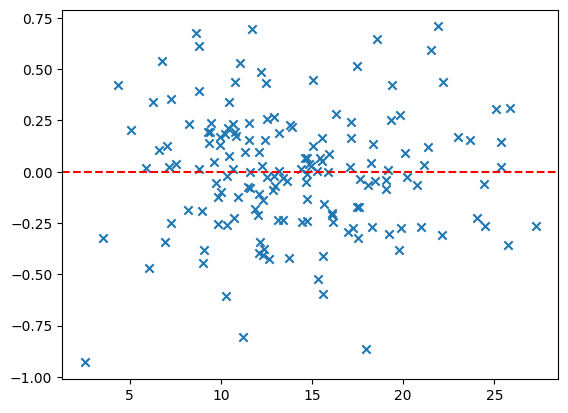

In [28]:
targeted_pipe.fit(X_train, y_train)
pred = targeted_pipe.predict(X_train)
print(f"train R²: {r2_score(y_train, pred):.4f}")
print(f"train RMSE: {np.sqrt(mean_squared_error(y_train, pred)):.3f}")

plt.scatter(pred, y_train - pred, marker='x')
plt.axhline(0, c='r', ls='--')

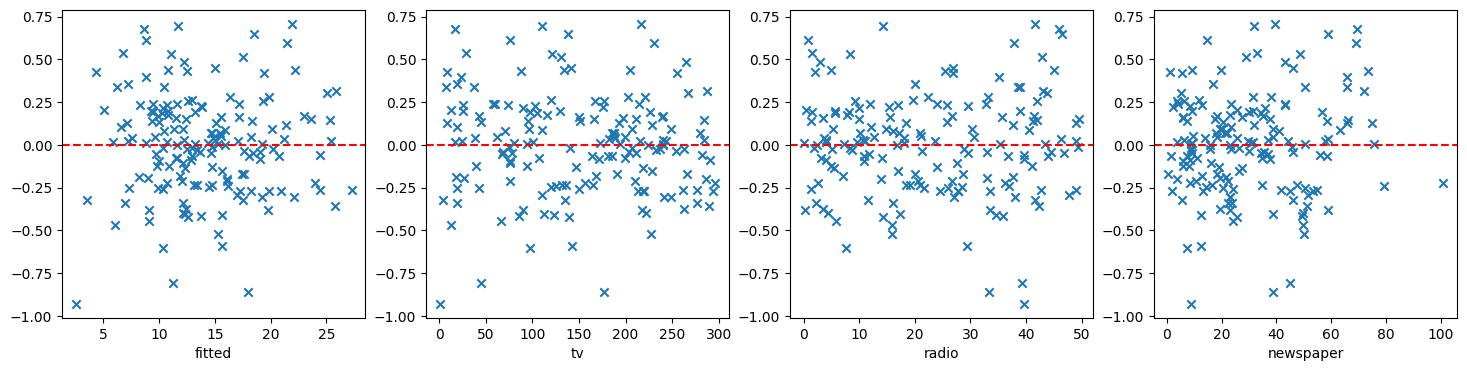

In [29]:
resid = y_train - pred
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].scatter(pred, resid, marker='x'); axes[0].axhline(0, c='r', ls='--')
axes[0].set_xlabel('fitted')
for ax, col in zip(axes[1:], ['tv', 'radio', 'newspaper']):
    ax.scatter(X_train[col], resid, marker='x'); ax.axhline(0, c='r', ls='--')
    ax.set_xlabel(col)

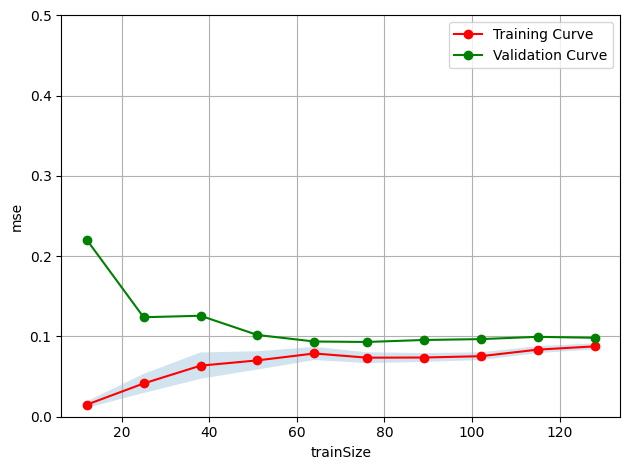

In [30]:
train_sizeF,train_scoreF,test_scoreF=learning_curve(targeted_pipe,X_train,y_train,scoring='neg_mean_squared_error',cv=cvfolds,train_sizes=np.linspace(0.1,1,10),random_state=RANDOM_STATE)
train_meanF, train_stdF = -train_scoreF.mean(1), train_scoreF.std(1)
plt.figure()
plt.plot(train_sizeF,train_meanF,'o-',c='r',label='Training Curve')
plt.plot(train_sizeF,-test_scoreF.mean(axis=1),'o-',c='g',label='Validation Curve')
plt.fill_between(train_sizeF, train_meanF - train_stdF, train_meanF + train_stdF, alpha=0.2)
plt.xlabel('trainSize')
plt.ylabel('mse')
plt.legend(loc='best');plt.grid(True)
plt.ylim(0,0.5)
plt.tight_layout()

Interpretation

In [31]:
from statsmodels.stats.diagnostic import het_breuschpagan
lm, lm_p, f, f_p = het_breuschpagan(m.resid, m.model.exog)
print(f"Breusch-Pagan p = {lm_p:.4f}")

NameError: name 'm' is not defined

In [ ]:
import statsmodels.formula.api as smf
X_sm = sm.add_constant(targeted_features(X_train))
m = sm.OLS(y_train, X_sm).fit()
m_robust = sm.OLS(y_train, X_sm).fit(cov_type='HC3')
rlm = sm.RLM(y_train, X_sm, M=sm.robust.norms.HuberT()).fit()

comp = pd.DataFrame({
    'ols_coef':    m.params,
    'hc3_se':      m_robust.bse,
    'rlm_coef':    rlm.params,
    'rlm_se':      rlm.bse,
})
comp['coef_diff_in_hc3_se'] = (comp['rlm_coef'] - comp['ols_coef']) / comp['hc3_se']
print(comp.round(4))
print(m_robust.summary())

       ols_coef  hc3_se  rlm_coef  rlm_se  coef_diff_in_hc3_se
const   -0.5438  0.3008   -0.4363  0.1917               0.3572
x1       2.1221  0.0624    2.0982  0.0394              -0.3836
x2       0.0485  0.0034    0.0485  0.0029               0.0161
x3       0.0010  0.0000    0.0010  0.0000               0.0770
                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 1.303e+04
Date:                Thu, 23 Jul 2026   Prob (F-statistic):          5.58e-187
Time:                        19:19:12   Log-Likelihood:                -33.186
No. Observations:                 160   AIC:                             74.37
Df Residuals:                     156   BIC:                             86.67
Df Model:                           3                

In [ ]:

test_pred = targeted_pipe.predict(X_test)
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_pred)):.3f}")
print(f"Test R²:   {r2_score(y_test, test_pred):.4f}")

Test RMSE: 0.360
Test R²:   0.9959


In [ ]:
X_test_sm = sm.add_constant(targeted_features(X_test))
pred = m.get_prediction(X_test_sm)

out = pred.summary_frame(alpha=0.05)
out.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,16.957361,0.029926,16.898250,17.016473,16.358815,17.555908
1,22.262770,0.050631,22.162759,22.362781,21.658812,22.866728
2,21.149806,0.047865,21.055260,21.244353,20.546729,21.752884
3,7.068711,0.066824,6.936714,7.200709,6.458640,7.678783
4,24.048259,0.059580,23.930570,24.165947,23.441123,24.655395


Breusch-Pagan p = 0.0042
